In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 
from plotting_helper import *
#%matplotlib inline

figures_path = 'figures/'
palette = plt.rcParams['axes.prop_cycle'].by_key()['color']  



def simulation_wrapper(state0, params, update, sim_time, dt): 
    #euler method to see behaviour quickly
    
    states = np.zeros([int(sim_time/dt)+1, state0.shape[0], state0.shape[1]])
    states[0] = state0
    
    for t in range(int(sim_time/dt)): 
        states[t+1] = update(params, states[t], dt)
        
    return states[1:]

def model_equation(parameters, state_var, dt ):
    #parmeters are: 
    #alpha, beta, and gamma (initation, elongation, degradation) rate and R (numer of total ribosomes)
    
    #parameters is a dictionary with the different parameters 
    #we just read them out below to return the updated amounts of interactions
    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    r = parameters['R'] - np.sum(xr_vec)  #concentration of free ribosomes

    new_x_vec = x_vec + dt * (-parameters['α']  * r * x_vec  + parameters['β'] * xr_vec)
    new_xr_vec = xr_vec + dt * (parameters['α'] * r *  x_vec - parameters['β'] * xr_vec)
    new_y_vec = y_vec + dt * ( parameters['β'] * xr_vec - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec




The system described by the differential equations is the simplest of the initiation/ elongation process possible. The only extra assumptionwe are making is that for a protein to assemble we need a reseouce (aminoacid) which is not infinitifely available.

One thing we ignore here: Stricly speaking initiation needs protein resource as well. However, each initiation needs one loaded tRNA which is the same for both. Initiation is not length dependend as the ribosome attaches at the 5' end of the mRNA string and than travels to the start codon. 

We first look at the dependence of the realtive protein synthesis on the ribosomal quantaty with a small amount of mRNA strings (1 per gene), 5 genes in total.

In [2]:
#set parameters: 
rng = np.random.RandomState(seed = 5)
γ = 0.05
α = 0.1
x_init = 1
sim_time = 100 #should be enough
dt = 0.001

In [3]:
Ns = np.array([2,6])#5
Yfactor = np.arange(0.5,2.2,0.5) #4
Rs = np.linspace(0.01,10,20)

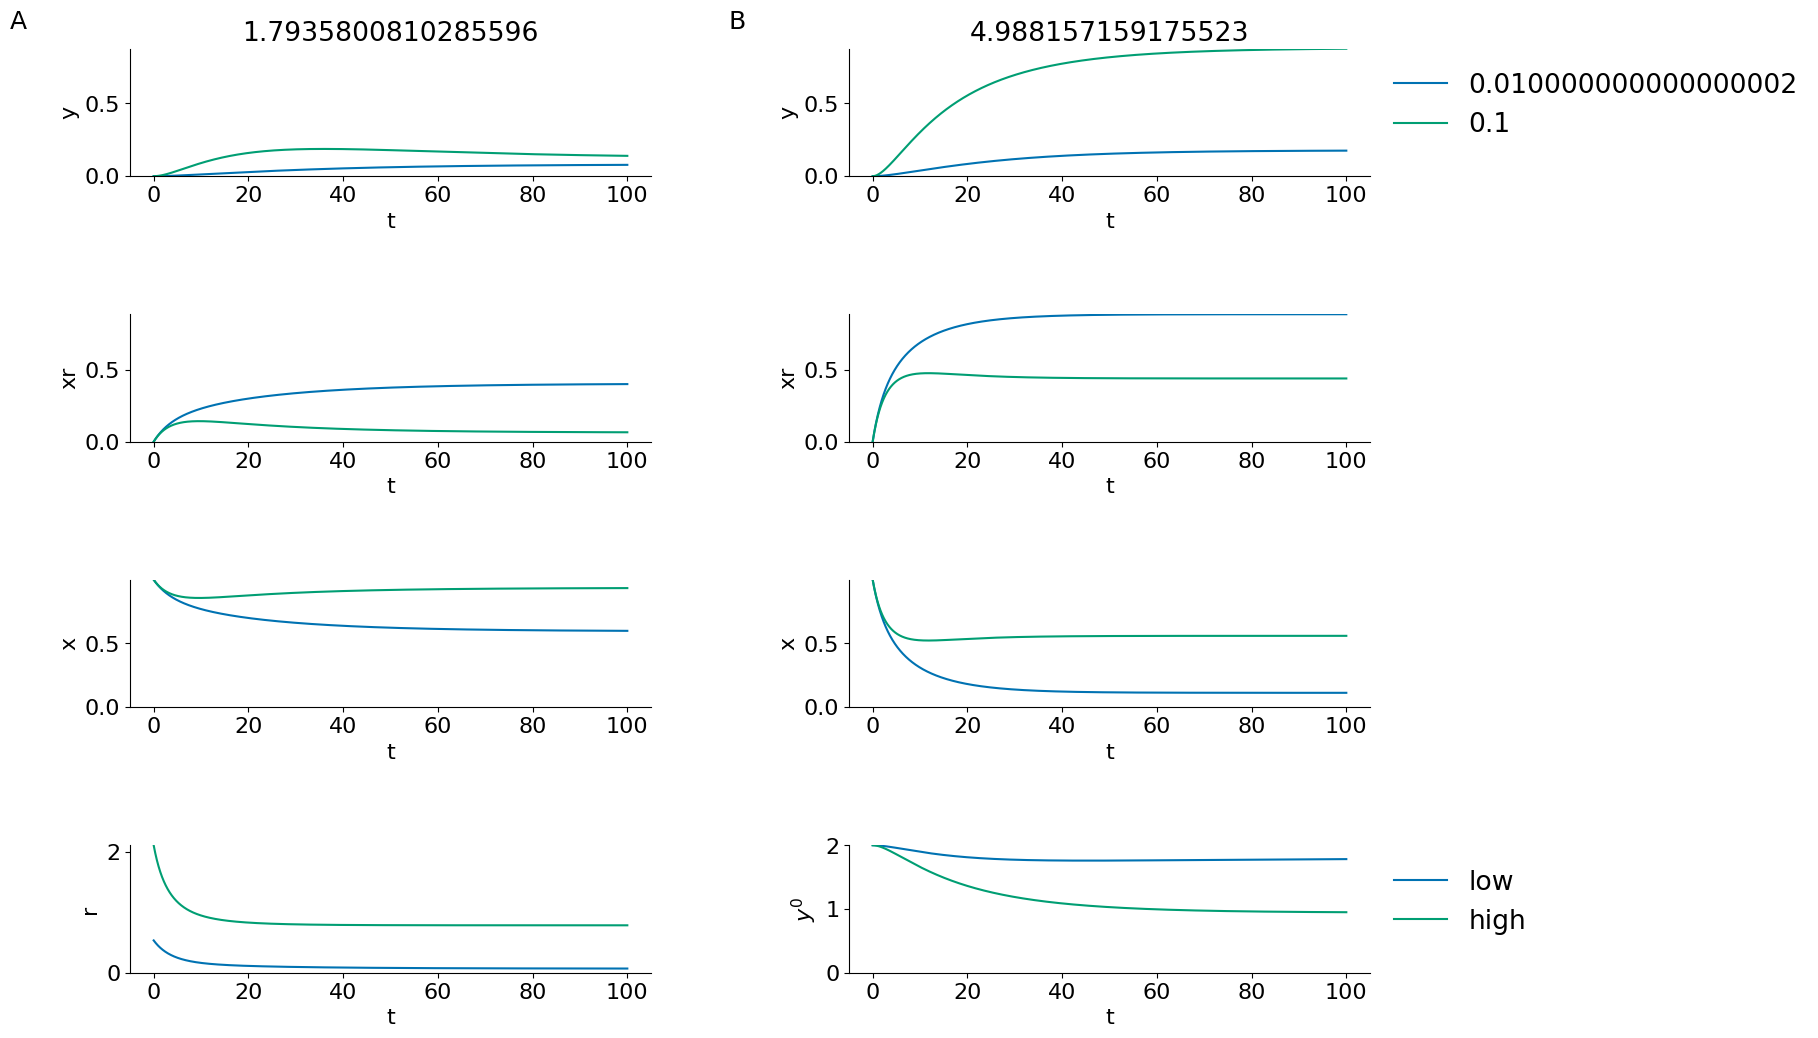

Ratio (short/long) in low condition:1.7935800810285596
Ratio (short/long) in high condition:4.988157159175523


In [4]:
N = 2 #number of genes/mRNA with differeng length
l = np.linspace(0.1,1,N)
# elongation < initiation
β = α * l # 

low = 1
high = 4

#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = β
parameters['γ'] = γ
parameters['l'] = l
parameters['Y_max'] = N #this is arbitrary for now 

#initial condition of all mRNA
x0 = np.ones([N])*x_init

#ribsome concentrations
results = np.zeros([Rs.shape[0],N])


init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 

parameters['R'] = Rs[low]

baseline_low = simulation_wrapper(init_state,parameters,model_equation, sim_time, dt) 


parameters['R'] = Rs[high]
baseline_high = simulation_wrapper(init_state,parameters,model_equation, sim_time, dt) 

layout = '''
    AAB
    AAB
    AAB
    AAB
    AAB
    AAB
    AAB
    '''



fig = plt.figure(figsize=(16, 12))

height_ratios = [1,0.1,1,0.1,1,0.1,1]
width_ratios = [1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()


maxy = np.amax([np.amax(baseline_low[:,2,:]), np.amax(baseline_high[:,2,:])])
maxxr = np.amax([np.amax(baseline_low[:,1,:]), np.amax(baseline_high[:,1,:])])
maxx = np.amax([np.amax(baseline_low[:,0,:]), np.amax(baseline_high[:,0,:])])

ax = fig.add_subplot(gs[0,0])
ax.plot(np.arange(0,sim_time,dt), baseline_low[:,2,0], label = β[0])
ax.plot(np.arange(0,sim_time,dt), baseline_low[:,2,1], label = β[1])
ax.set_ylabel('y')
ax.set_xlabel('t')
ax.set_ylim(0,maxy)
ax.set_title(baseline_low[-1,2,1]/baseline_low[-1,2,0])
clear_axes(ax)

ax = fig.add_subplot(gs[0,2])
ax.plot(np.arange(0,sim_time,dt), baseline_high[:,2,0], label = β[0])
ax.plot(np.arange(0,sim_time,dt), baseline_high[:,2,1], label = β[1])
ax.set_ylabel('y')
ax.set_xlabel('t')
ax.set_ylim(0,maxy)
ax.set_title(baseline_high[-1,2,1]/baseline_high[-1,2,0])
ax.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)

ax = fig.add_subplot(gs[2,0])
ax.plot(np.arange(0,sim_time,dt), baseline_low[:,1,0], label = β[0])
ax.plot(np.arange(0,sim_time,dt), baseline_low[:,1,1], label = β[1])
ax.set_ylabel('xr')
ax.set_xlabel('t')
ax.set_ylim(0,maxxr)
clear_axes(ax)

ax = fig.add_subplot(gs[2,2])
ax.plot(np.arange(0,sim_time,dt), baseline_high[:,1,0], label = β[0])
ax.plot(np.arange(0,sim_time,dt), baseline_high[:,1,1], label = β[1])
ax.set_ylabel('xr')
ax.set_xlabel('t')
ax.set_ylim(0,maxxr)
clear_axes(ax)

ax = fig.add_subplot(gs[4,0])
ax.plot(np.arange(0,sim_time,dt), baseline_low[:,0,0], label = β[0])
ax.plot(np.arange(0,sim_time,dt), baseline_low[:,0,1], label = β[1])
ax.set_ylabel('x')
ax.set_xlabel('t')
ax.set_ylim(0,maxx)
clear_axes(ax)

ax = fig.add_subplot(gs[4,2])
ax.plot(np.arange(0,sim_time,dt), baseline_high[:,0,0], label = β[0])
ax.plot(np.arange(0,sim_time,dt), baseline_high[:,0,1], label = β[1])
ax.set_ylabel('x')
ax.set_xlabel('t')
ax.set_ylim(0,maxx)
clear_axes(ax)

ax = fig.add_subplot(gs[6,0])
ax.plot(np.arange(0,sim_time,dt), Rs[low]-np.sum(baseline_low[:,1,:], axis = 1))
ax.plot(np.arange(0,sim_time,dt), Rs[high]-np.sum(baseline_high[:,1,:], axis = 1))
ax.set_ylabel('r')
ax.set_xlabel('t')
ax.set_ylim(0,Rs[high])
clear_axes(ax)

ax = fig.add_subplot(gs[6,2])
ax.plot(np.arange(0,sim_time,dt), N-np.sum(baseline_low[:,2,:], axis = 1), label = 'low')
ax.plot(np.arange(0,sim_time,dt), N-np.sum(baseline_high[:,2,:], axis = 1), label = 'high')
ax.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
ax.set_ylabel('$y^0$')
ax.set_xlabel('t')
ax.set_ylim(0,N)
clear_axes(ax)

plt.show()

print('Ratio (short/long) in low condition:'+str(baseline_low[-1,2,1]/baseline_low[-1,2,0]) )
print('Ratio (short/long) in high condition:'+str(baseline_high[-1,2,1]/baseline_high[-1,2,0]) )


IndexError: list index out of range

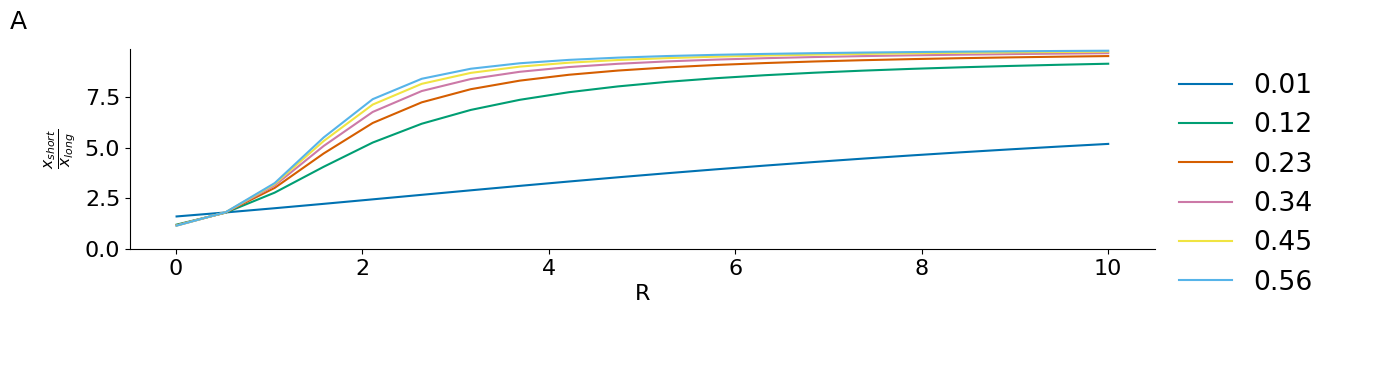

In [20]:
n = 2
αs = np.linspace(0.01,1,10)
results = np.zeros([αs.shape[0], Rs.shape[0], n])
for yind, yf in enumerate(αs): 
    #increasing total sum
    l = np.linspace(0.1,1,n)
    β = α * l #was * before
    #prepare parameter dictionary
    parameters = dict()
    parameters['α'] = yf
    parameters['β'] = β
    parameters['γ'] = γ
    parameters['l'] = l
    parameters['Y_max'] = n*1 #relative to mRNA amount

    #initial condition of all mRNA
    x0 = np.ones([n])*x_init

    for r in range(Rs.shape[0]):

        parameters['R'] = Rs[r]

        init_state =np.array([x0, np.zeros([n]),np.zeros([n])]) 

        baseline = simulation_wrapper(init_state,parameters,model_equation, sim_time, dt) 
        results[yind, r,:]= baseline[-1,2,:]

layout = '''
    AA
    AA
    '''



fig = plt.figure(figsize=(16, 4))

height_ratios = [1,0.1]
width_ratios = [1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'A':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='A', postfix='', offset_left=1.2)
for a in list('A'):
    axes[a].set_axis_off()

miny = np.amin(results[:,:,1]/results[:,:,0])
maxy = np.amax(results[:,:,1]/results[:,:,0])
ax1 = fig.add_subplot(gs[0,0])
for yind, yf in enumerate(αs): 
    l = np.linspace(0.1,1,n)/n
    β = α * l
    #we define short and long here with beta not with l (as beta is not anti-proportional in this setting)
    ax1.plot(Rs, results[yind,:,1]/results[yind,:,0], label = yf, color = palette[yind])
    ax1.set_xlabel('R')
    ax1.set_ylabel('$\\frac{x_{short}}{x_{long}}$')
    ax1.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    ax1.set_ylim(0, maxy)


    clear_axes(ax1)

plt.show()


In [6]:
results = np.zeros([Yfactor.shape[0], Ns.shape[0], Rs.shape[0], Ns[-1],3])

for yind, yf in enumerate(Yfactor): 
    for nind, n in enumerate(Ns): 
        #set l so that the sum of l is constant
        l = np.linspace(0.1,1,n)/n
        β = α * l
        #prepare parameter dictionary
        parameters = dict()
        parameters['α'] = α
        parameters['β'] = β
        parameters['γ'] = γ
        parameters['l'] = l
        parameters['Y_max'] = n*yf #relative to mRNA amount

        #initial condition of all mRNA
        x0 = np.ones([n])*x_init

        for r in range(Rs.shape[0]):

            parameters['R'] = Rs[r]

            init_state =np.array([x0, np.zeros([n]),np.zeros([n])]) 

            baseline = simulation_wrapper(init_state,parameters,model_equation, sim_time, dt) 
            results[yind, nind, r, :n,:]= baseline[-1,:,:].T



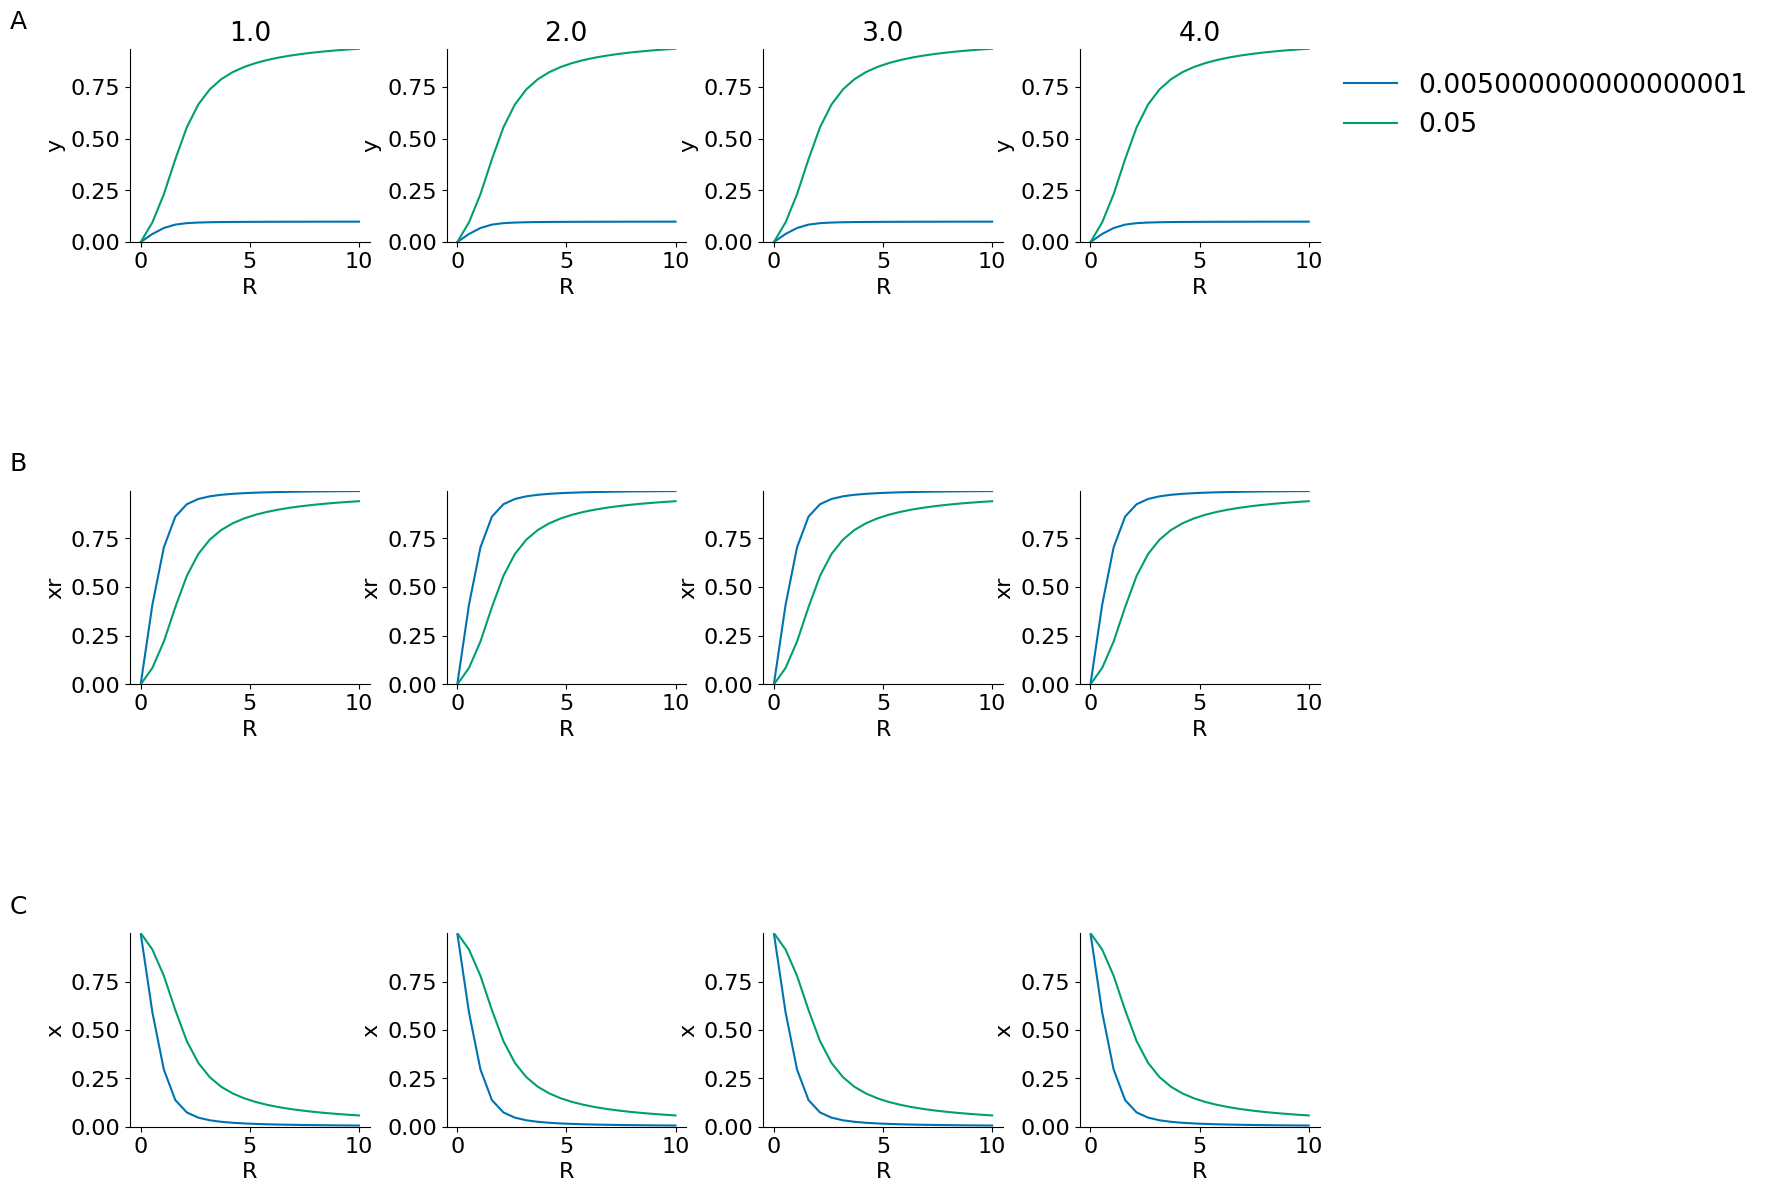

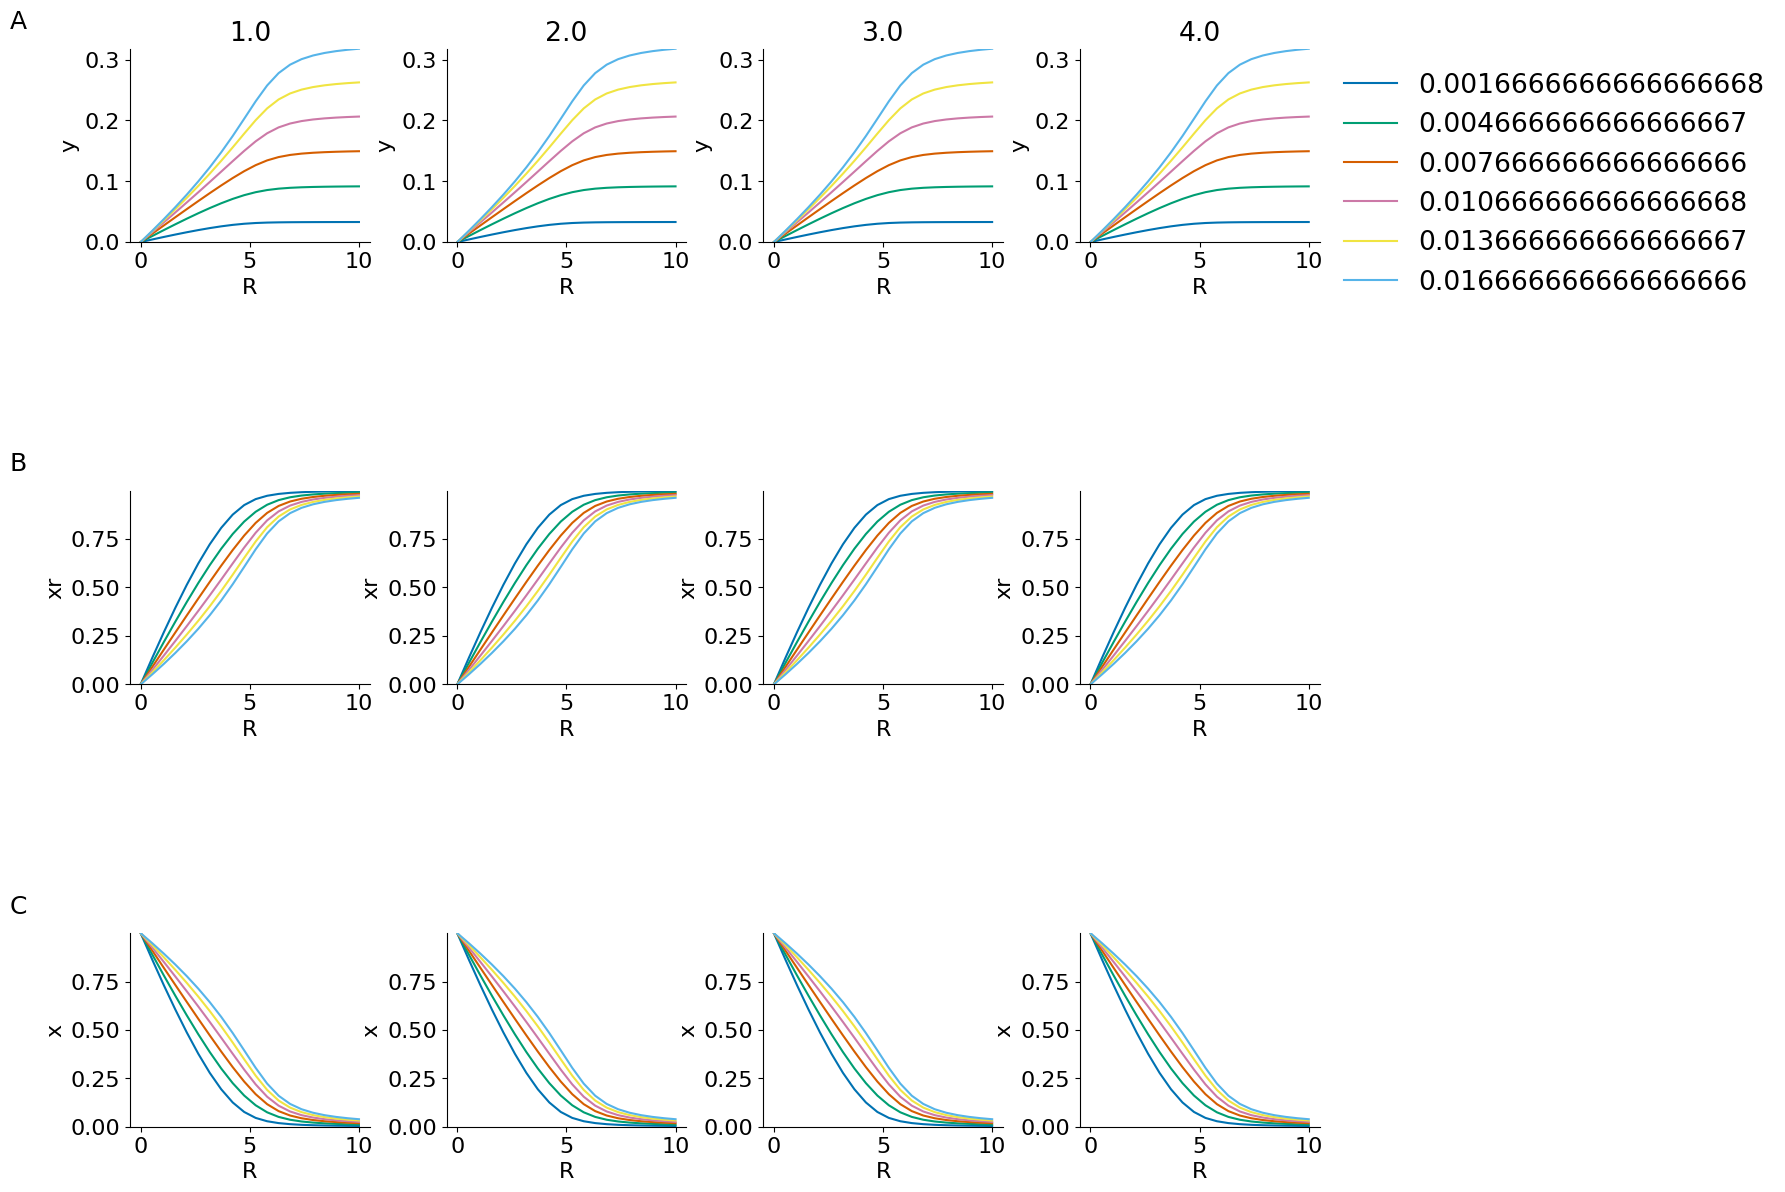

In [7]:


layout = '''
    AAAAAAAA
    AAAAAAAA
    BBBBBBBB
    BBBBBBBB
    CCCCCCCC
    
    '''

for nind, n in enumerate(Ns): 

    fig = plt.figure(figsize=(16, 14))

    height_ratios = [1,0.2,1,0.2,1]
    width_ratios = [1,0.1,1,0.1,1,0.1,1,0.1]


    specs, gs = panel_specs(layout, fig=fig)
    gs.set_height_ratios(height_ratios)
    gs.set_width_ratios(width_ratios)
    gs.hspace=0.8
    axes = {}
    for letter in 'ABC':
        axes[letter] = ax = fig.add_subplot(specs[letter])
    label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
    for a in list('ABC'):
        axes[a].set_axis_off()
        
    miny = np.amin(results[:,nind,:,:,2])
    maxy = np.amax(results[:,nind,:,:,2])
    minxr = np.amin(results[:,nind,:,:,1])
    maxxr = np.amax(results[:,nind,:,:,1])
    minx = np.amin(results[:,nind,:,:,0])
    maxx = np.amax(results[:,nind,:,:,0])

    for yind, yf in enumerate(Yfactor): 
        ax1 = fig.add_subplot(gs[0,yind*2])
        ax2 = fig.add_subplot(gs[2,yind*2])
        ax3 = fig.add_subplot(gs[4,yind*2])
        ax1.set_title(yf*2)
        l = np.linspace(0.1,1,n)/n
        β = α * l
        for i in range(n):
            ax1.plot(Rs, results[yind,nind,:,i,2], label = β[i], color = palette[i])
            ax2.plot(Rs, results[yind,nind,:,i,1], label = β[i], color = palette[i])
            ax3.plot(Rs, results[yind,nind,:,i,0], label = β[i], color = palette[i])
        ax1.set_xlabel('R')
        ax2.set_xlabel('R')
        ax3.set_xlabel('R')
        ax1.set_ylabel('y')
        ax2.set_ylabel('xr')
        ax3.set_ylabel('x')
        ax1.set_ylim(0, maxy)
        ax2.set_ylim(0, maxxr)
        ax3.set_ylim(0, maxx)

        clear_axes(ax1)
        clear_axes(ax2)
        clear_axes(ax3)
    ax1.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    plt.show()

    


In [8]:
results = np.zeros([Yfactor.shape[0], Ns.shape[0], Rs.shape[0], Ns[-1],3])
for yind, yf in enumerate(Yfactor): 
    for nind, n in enumerate(Ns): 
        #set l so that the sum of l is constant
        l = np.linspace(0.1,1,n)/n
        β = α * l
        #prepare parameter dictionary
        parameters = dict()
        parameters['α'] = α
        parameters['β'] = β
        parameters['γ'] = γ
        parameters['l'] = l
        parameters['Y_max'] = 2*yf #constant

        #initial condition of all mRNA
        x0 = np.ones([n])*x_init

        for r in range(Rs.shape[0]):

            parameters['R'] = Rs[r]

            init_state =np.array([x0, np.zeros([n]),np.zeros([n])]) 

            baseline = simulation_wrapper(init_state,parameters,model_equation, sim_time, dt) 
            results[yind, nind, r, :n]= baseline[-1,:,:].T


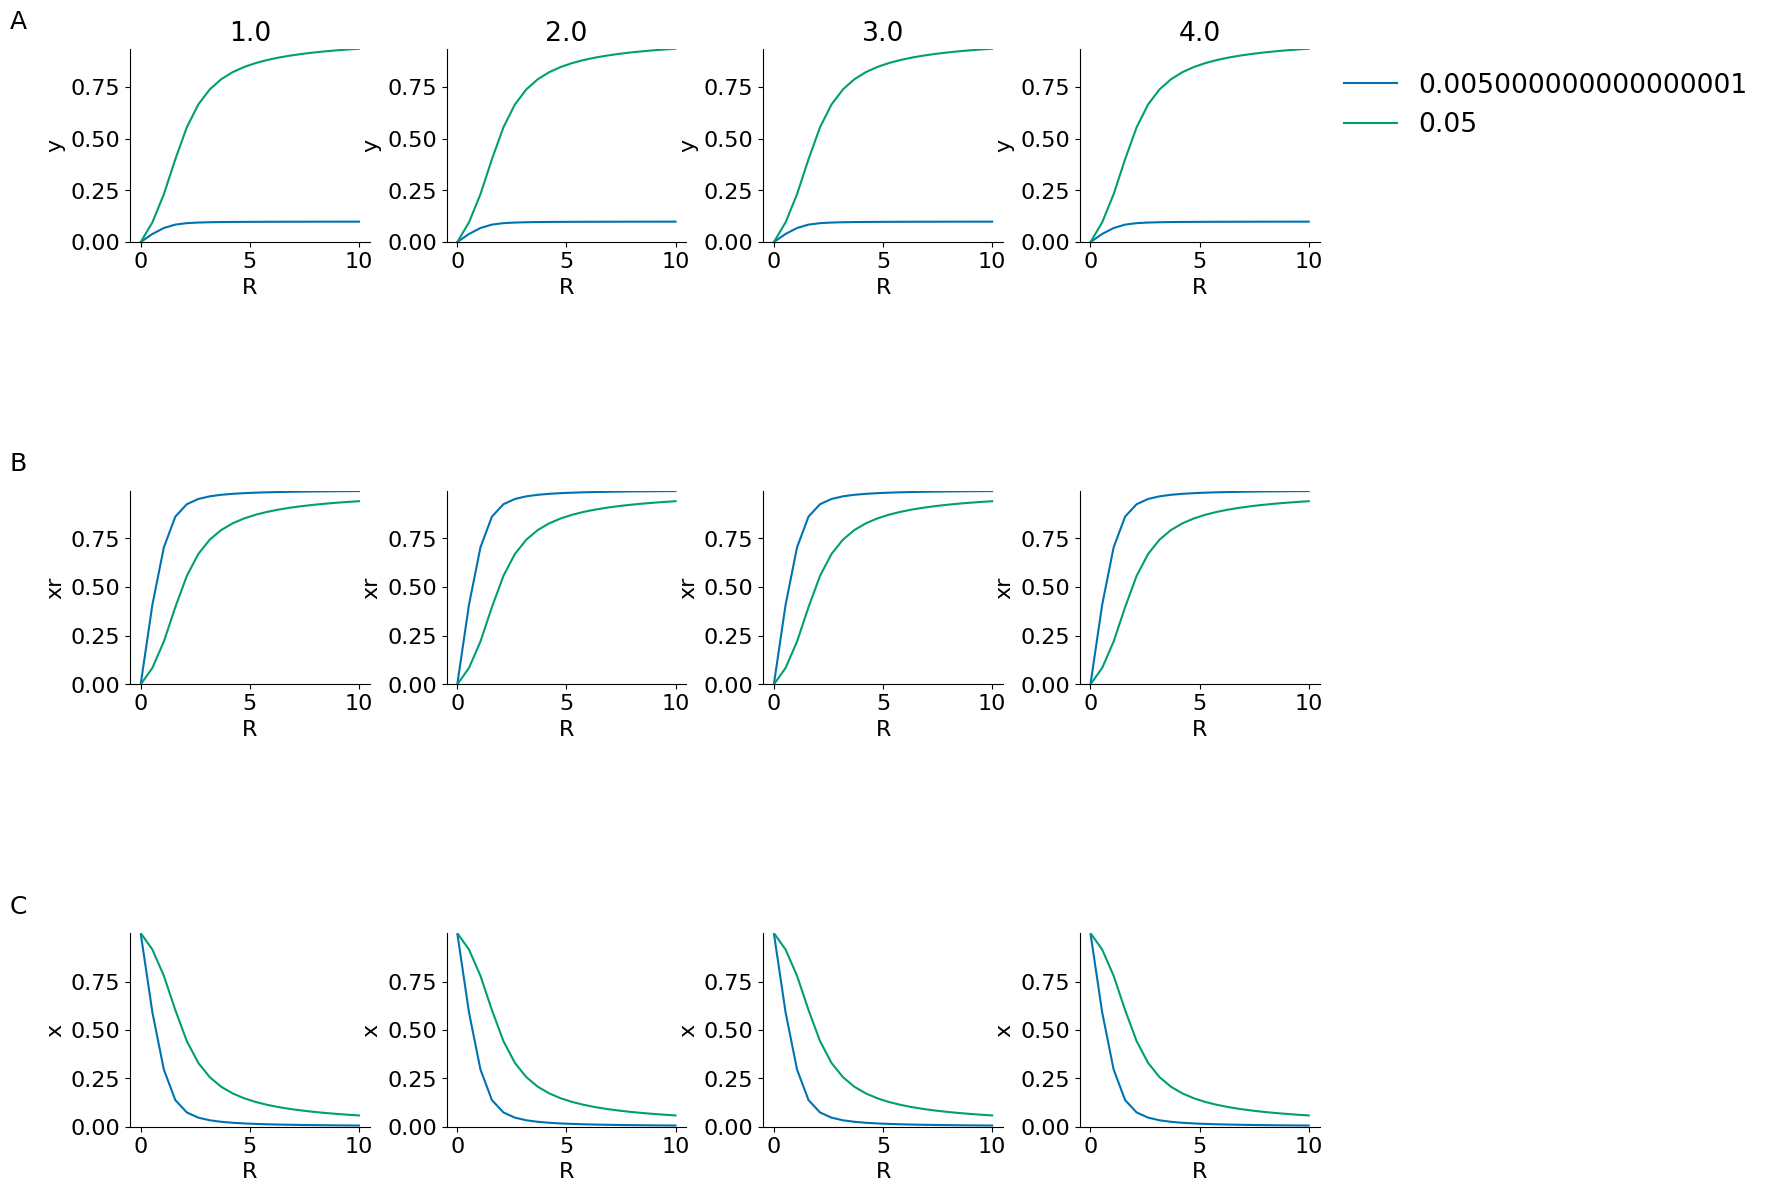

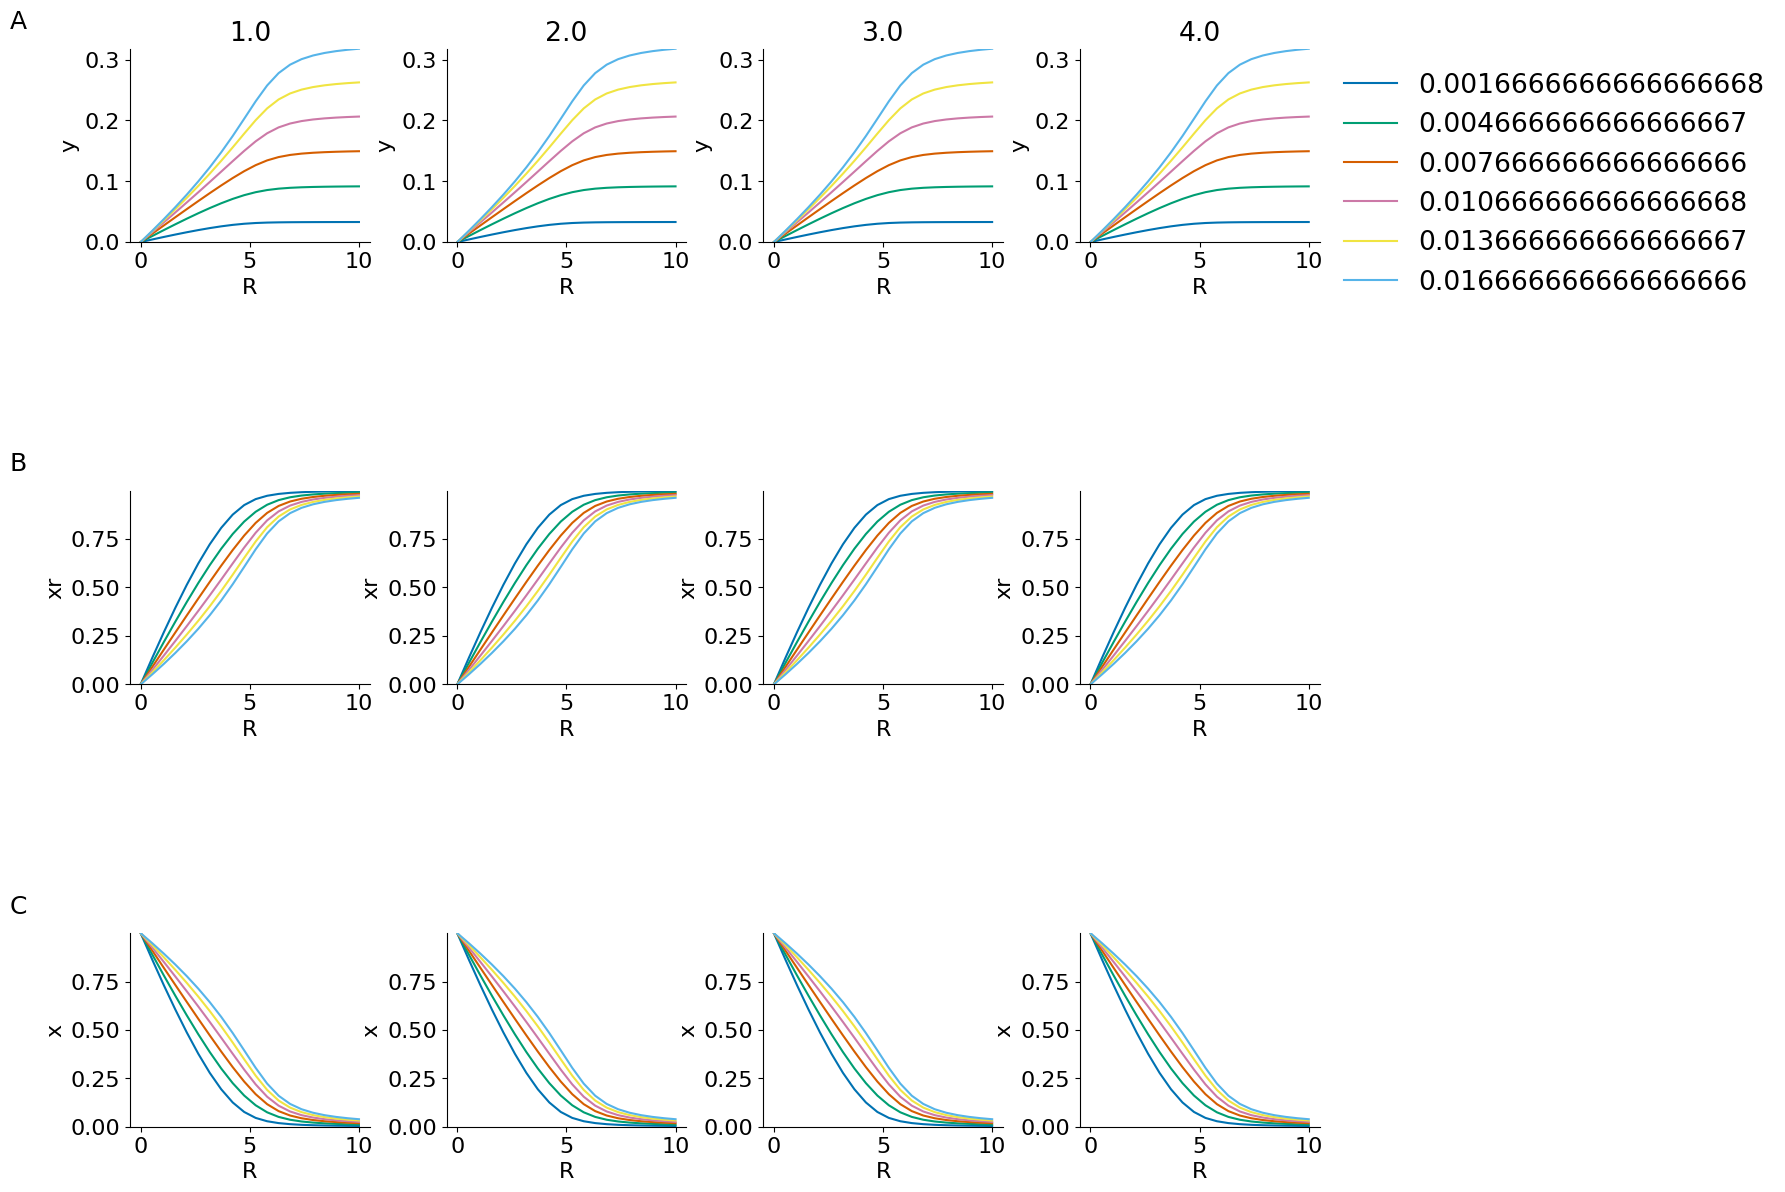

In [9]:
layout = '''
    AAAAAAAA
    AAAAAAAA
    BBBBBBBB
    BBBBBBBB
    CCCCCCCC
    
    '''

for nind, n in enumerate(Ns): 

    fig = plt.figure(figsize=(16, 14))

    height_ratios = [1,0.2,1,0.2,1]
    width_ratios = [1,0.1,1,0.1,1,0.1,1,0.1]


    specs, gs = panel_specs(layout, fig=fig)
    gs.set_height_ratios(height_ratios)
    gs.set_width_ratios(width_ratios)
    gs.hspace=0.8
    axes = {}
    for letter in 'ABC':
        axes[letter] = ax = fig.add_subplot(specs[letter])
    label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
    for a in list('ABC'):
        axes[a].set_axis_off()
        
    miny = np.amin(results[:,nind,:,:,2])
    maxy = np.amax(results[:,nind,:,:,2])
    minxr = np.amin(results[:,nind,:,:,1])
    maxxr = np.amax(results[:,nind,:,:,1])
    minx = np.amin(results[:,nind,:,:,0])
    maxx = np.amax(results[:,nind,:,:,0])

    for yind, yf in enumerate(Yfactor): 
        ax1 = fig.add_subplot(gs[0,yind*2])
        ax2 = fig.add_subplot(gs[2,yind*2])
        ax3 = fig.add_subplot(gs[4,yind*2])
        ax1.set_title(yf*2)
        l = np.linspace(0.1,1,n)/n
        β = α * l
        for i in range(n):
            ax1.plot(Rs, results[yind,nind,:,i,2], label = β[i], color = palette[i])
            ax2.plot(Rs, results[yind,nind,:,i,1], label = β[i], color = palette[i])
            ax3.plot(Rs, results[yind,nind,:,i,0], label = β[i], color = palette[i])
        ax1.set_xlabel('R')
        ax2.set_xlabel('R')
        ax3.set_xlabel('R')
        ax1.set_ylabel('y')
        ax2.set_ylabel('xr')
        ax3.set_ylabel('x')
        ax1.set_ylim(0, maxy)
        ax2.set_ylim(0, maxxr)
        ax3.set_ylim(0, maxx)

        clear_axes(ax1)
        clear_axes(ax2)
        clear_axes(ax3)
    ax1.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    plt.show()


In [10]:
results = np.zeros([Yfactor.shape[0], Ns.shape[0], Rs.shape[0], Ns[-1],3])
for yind, yf in enumerate(Yfactor): 
    for nind, n in enumerate(Ns): 
        #increasing total sum
        l = np.linspace(0.1,1,n)
        β = α * l
        #prepare parameter dictionary
        parameters = dict()
        parameters['α'] = α
        parameters['β'] = β
        parameters['γ'] = γ
        parameters['l'] = l
        parameters['Y_max'] = n*yf #relative to mRNA amount

        #initial condition of all mRNA
        x0 = np.ones([n])*x_init

        for r in range(Rs.shape[0]):

            parameters['R'] = Rs[r]

            init_state =np.array([x0, np.zeros([n]),np.zeros([n])]) 

            baseline = simulation_wrapper(init_state,parameters,model_equation, sim_time, dt) 
            results[yind, nind, r, :n]= baseline[-1,:,:].T

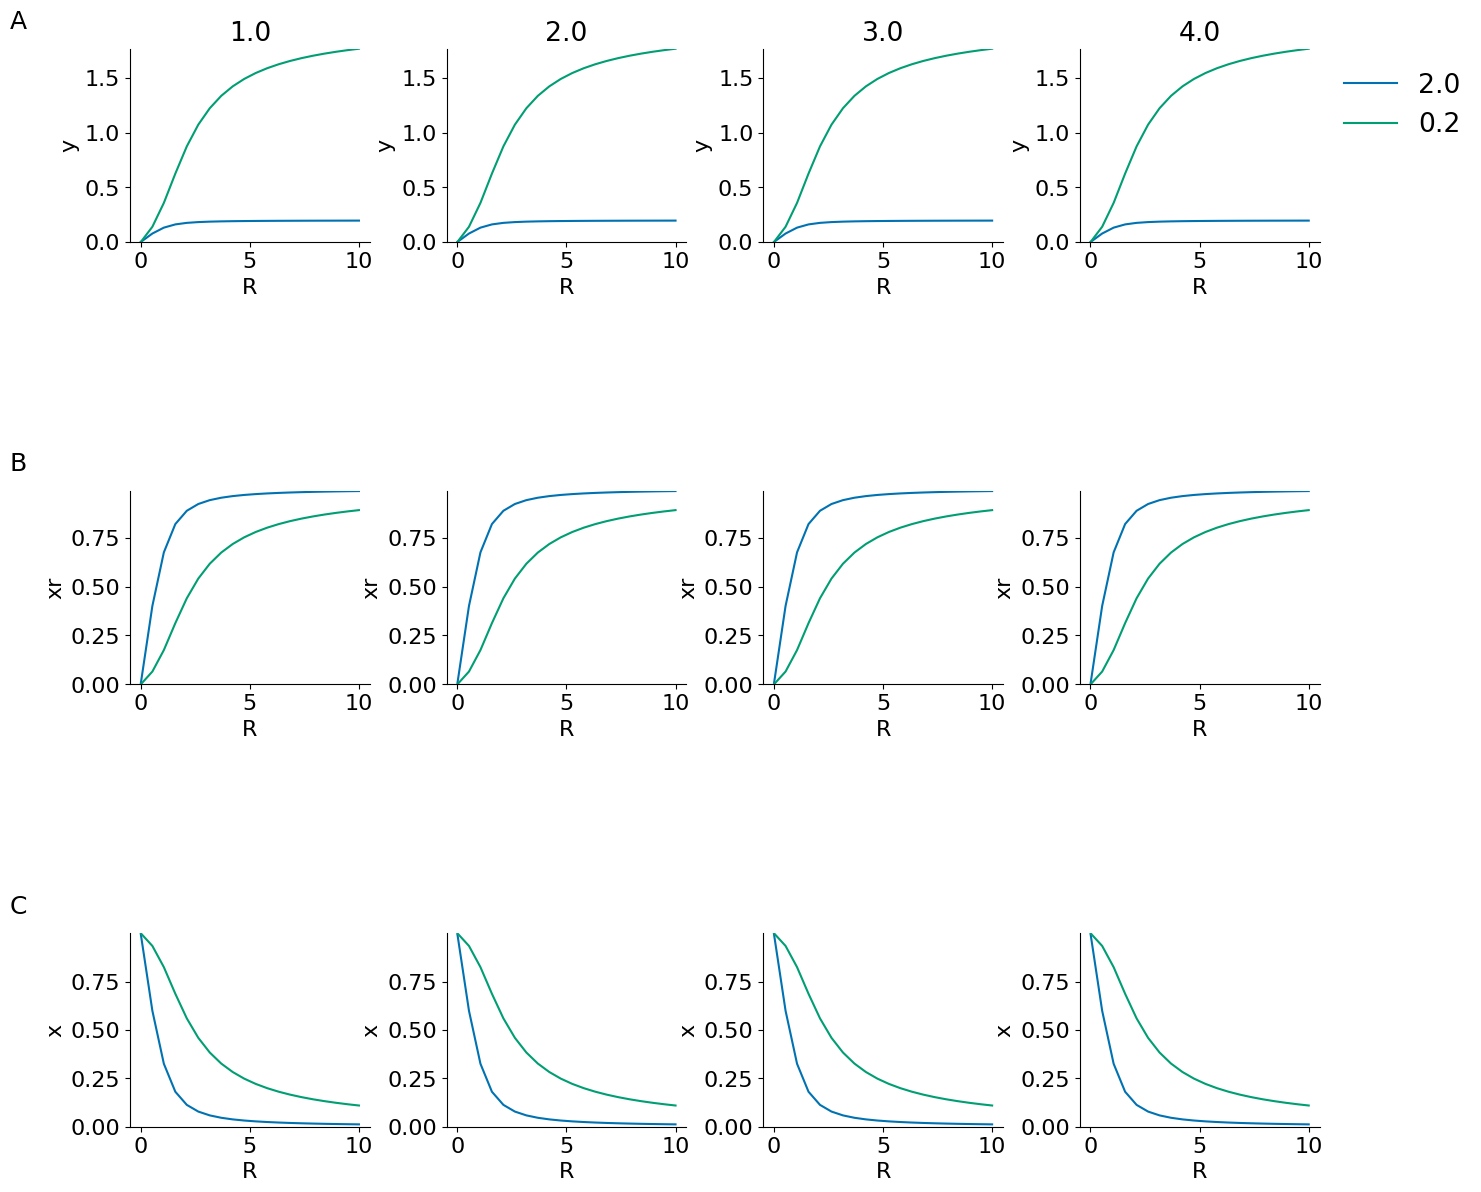

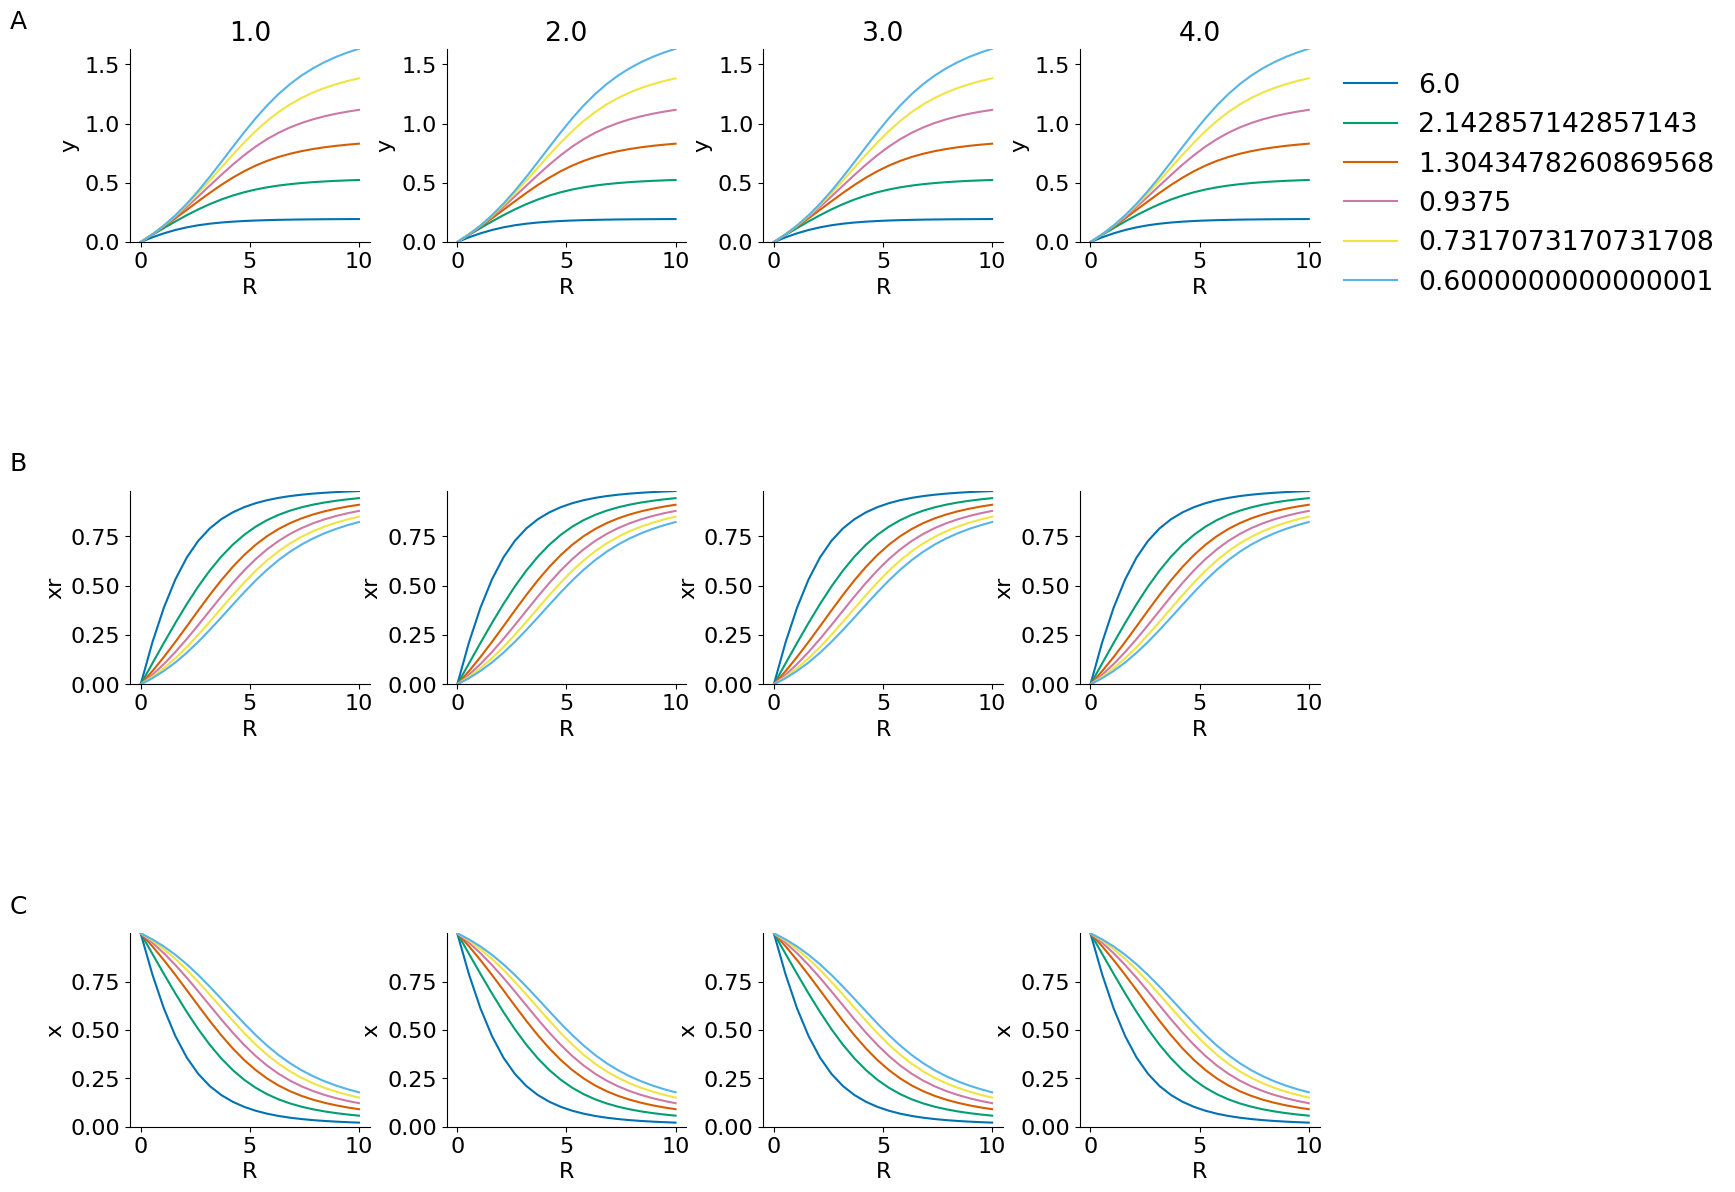

In [11]:
layout = '''
    AAAAAAAA
    AAAAAAAA
    BBBBBBBB
    BBBBBBBB
    CCCCCCCC
    
    '''

for nind, n in enumerate(Ns): 

    fig = plt.figure(figsize=(16, 14))

    height_ratios = [1,0.2,1,0.2,1]
    width_ratios = [1,0.1,1,0.1,1,0.1,1,0.1]


    specs, gs = panel_specs(layout, fig=fig)
    gs.set_height_ratios(height_ratios)
    gs.set_width_ratios(width_ratios)
    gs.hspace=0.8
    axes = {}
    for letter in 'ABC':
        axes[letter] = ax = fig.add_subplot(specs[letter])
    label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
    for a in list('ABC'):
        axes[a].set_axis_off()
        
    miny = np.amin(results[:,nind,:,:,2])
    maxy = np.amax(results[:,nind,:,:,2])
    minxr = np.amin(results[:,nind,:,:,1])
    maxxr = np.amax(results[:,nind,:,:,1])
    minx = np.amin(results[:,nind,:,:,0])
    maxx = np.amax(results[:,nind,:,:,0])

    for yind, yf in enumerate(Yfactor): 
        ax1 = fig.add_subplot(gs[0,yind*2])
        ax2 = fig.add_subplot(gs[2,yind*2])
        ax3 = fig.add_subplot(gs[4,yind*2])
        ax1.set_title(yf*2)
        l = np.linspace(0.1,1,n)/n
        β = α / l
        for i in range(n):
            ax1.plot(Rs, results[yind,nind,:,i,2], label = β[i], color = palette[i])
            ax2.plot(Rs, results[yind,nind,:,i,1], label = β[i], color = palette[i])
            ax3.plot(Rs, results[yind,nind,:,i,0], label = β[i], color = palette[i])
        ax1.set_xlabel('R')
        ax2.set_xlabel('R')
        ax3.set_xlabel('R')
        ax1.set_ylabel('y')
        ax2.set_ylabel('xr')
        ax3.set_ylabel('x')
        ax1.set_ylim(0, maxy)
        ax2.set_ylim(0, maxxr)
        ax3.set_ylim(0, maxx)

        clear_axes(ax1)
        clear_axes(ax2)
        clear_axes(ax3)
    ax1.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    plt.show()


In [12]:
results = np.zeros([Yfactor.shape[0], Ns.shape[0], Rs.shape[0], Ns[-1],3])
for yind, yf in enumerate(Yfactor): 
    for nind, n in enumerate(Ns): 
        #increasing total sum
        l = np.linspace(0.1,1,n)
        β = α * l
        #prepare parameter dictionary
        parameters = dict()
        parameters['α'] = α
        parameters['β'] = β
        parameters['γ'] = γ
        parameters['l'] = l
        parameters['Y_max'] = 2*yf #constant

        #initial condition of all mRNA
        x0 = np.ones([n])*x_init

        for r in range(Rs.shape[0]):

            parameters['R'] = Rs[r]

            init_state =np.array([x0, np.zeros([n]),np.zeros([n])]) 

            baseline = simulation_wrapper(init_state,parameters,model_equation, sim_time, dt) 
            results[yind, nind, r, :n]= baseline[-1,:,:].T

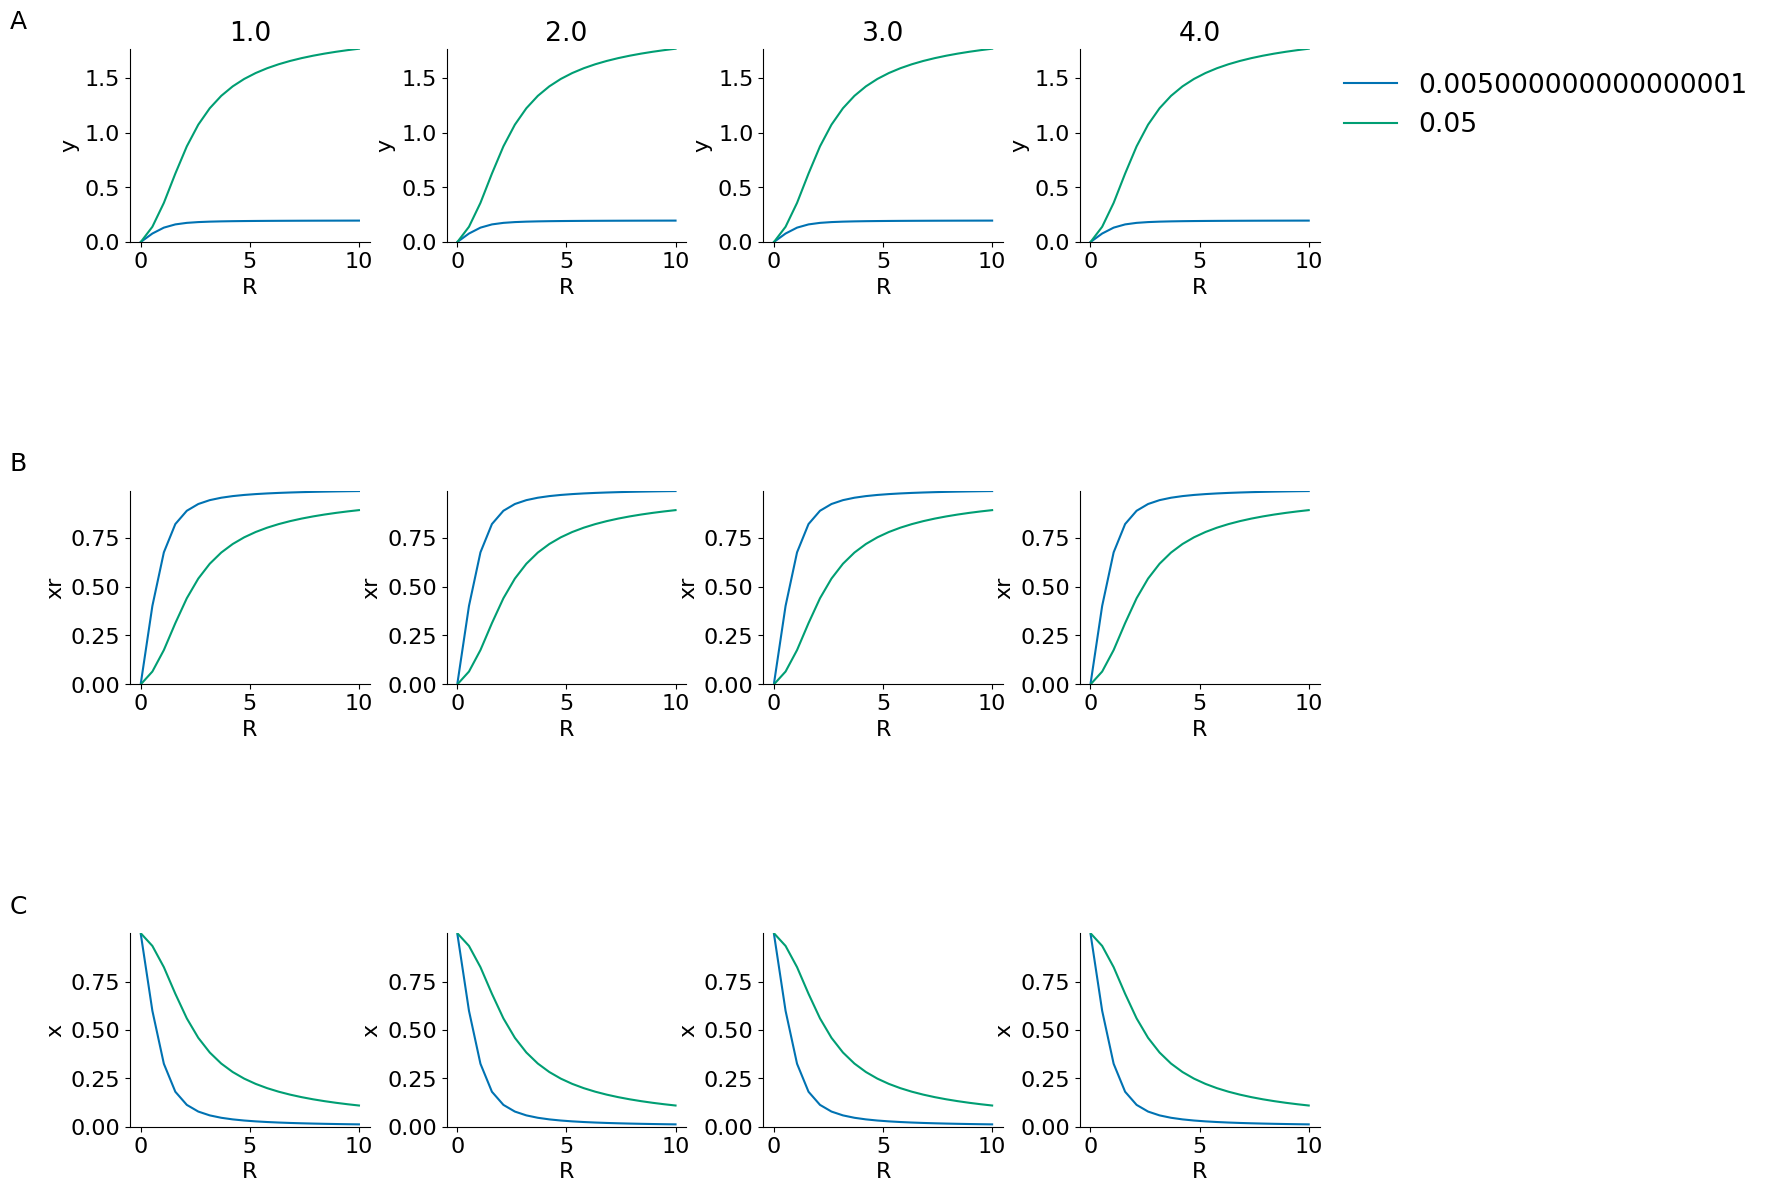

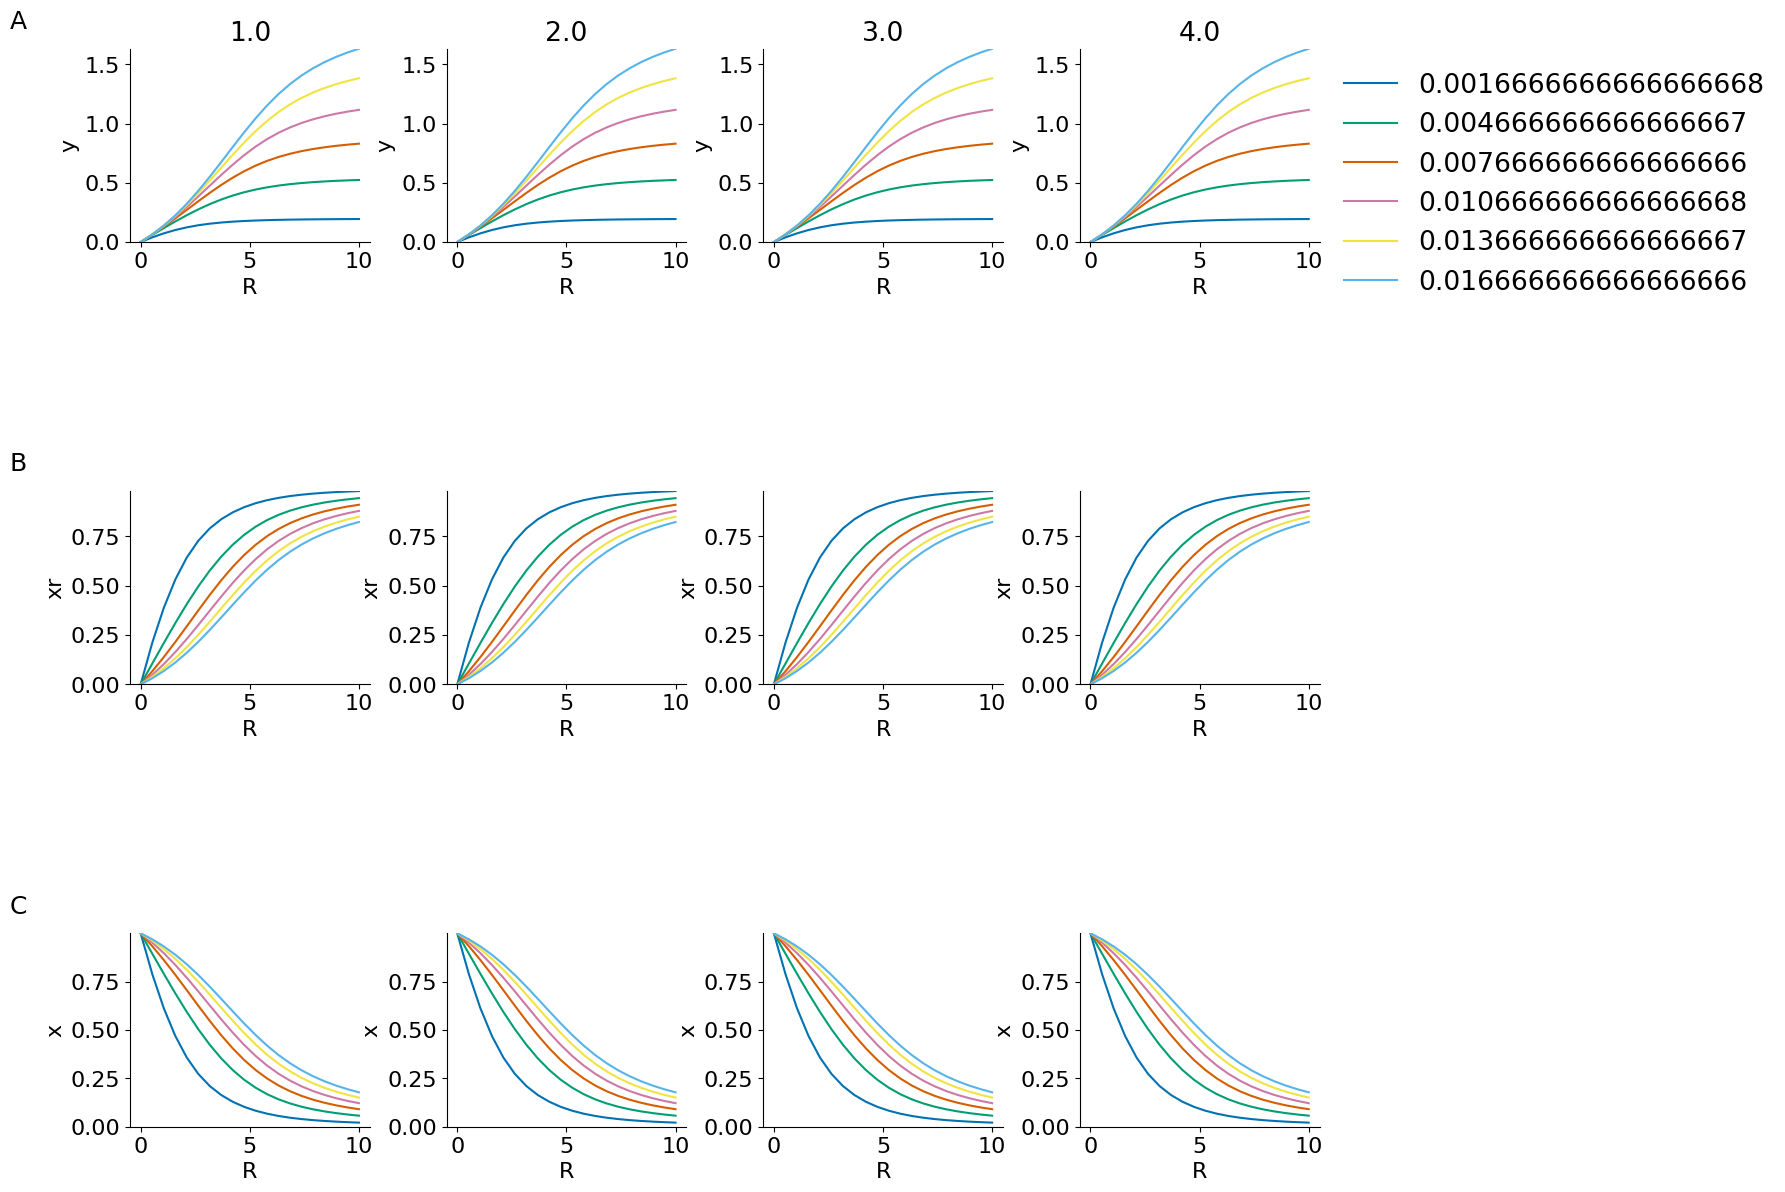

In [13]:
layout = '''
    AAAAAAAA
    AAAAAAAA
    BBBBBBBB
    BBBBBBBB
    CCCCCCCC
    
    '''

for nind, n in enumerate(Ns): 

    fig = plt.figure(figsize=(16, 14))

    height_ratios = [1,0.2,1,0.2,1]
    width_ratios = [1,0.1,1,0.1,1,0.1,1,0.1]


    specs, gs = panel_specs(layout, fig=fig)
    gs.set_height_ratios(height_ratios)
    gs.set_width_ratios(width_ratios)
    gs.hspace=0.8
    axes = {}
    for letter in 'ABC':
        axes[letter] = ax = fig.add_subplot(specs[letter])
    label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
    for a in list('ABC'):
        axes[a].set_axis_off()
        
    miny = np.amin(results[:,nind,:,:,2])
    maxy = np.amax(results[:,nind,:,:,2])
    minxr = np.amin(results[:,nind,:,:,1])
    maxxr = np.amax(results[:,nind,:,:,1])
    minx = np.amin(results[:,nind,:,:,0])
    maxx = np.amax(results[:,nind,:,:,0])

    for yind, yf in enumerate(Yfactor): 
        ax1 = fig.add_subplot(gs[0,yind*2])
        ax2 = fig.add_subplot(gs[2,yind*2])
        ax3 = fig.add_subplot(gs[4,yind*2])
        ax1.set_title(yf*2)
        l = np.linspace(0.1,1,n)/n
        β = α * l
        for i in range(n):
            ax1.plot(Rs, results[yind,nind,:,i,2], label = β[i], color = palette[i])
            ax2.plot(Rs, results[yind,nind,:,i,1], label = β[i], color = palette[i])
            ax3.plot(Rs, results[yind,nind,:,i,0], label = β[i], color = palette[i])
        ax1.set_xlabel('R')
        ax2.set_xlabel('R')
        ax3.set_xlabel('R')
        ax1.set_ylabel('y')
        ax2.set_ylabel('xr')
        ax3.set_ylabel('x')
        ax1.set_ylim(0, maxy)
        ax2.set_ylim(0, maxxr)
        ax3.set_ylim(0, maxx)

        clear_axes(ax1)
        clear_axes(ax2)
        clear_axes(ax3)
    ax1.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    plt.show()


In [17]:
n = 1
βs = np.linspace(0.1,1,6)
results = np.zeros([Yfactor.shape[0], βs.shape[0], Rs.shape[0],3])

for yind, yf in enumerate(Yfactor): 
    for βind, β in enumerate(βs): 
        #increasing total sum
        #prepare parameter dictionary
        parameters = dict()
        parameters['α'] = α
        parameters['β'] = β * α
        parameters['γ'] = γ
        parameters['l'] = l
        parameters['Y_max'] = yf #constant

        #initial condition of all mRNA
        x0 = np.ones([n])*x_init

        for r in range(Rs.shape[0]):

            parameters['R'] = Rs[r]

            init_state =np.array([x0, np.zeros([n]),np.zeros([n])]) 

            baseline = simulation_wrapper(init_state,parameters,model_equation, sim_time, dt) 
            results[yind, βind, r]= baseline[-1,:,0].T



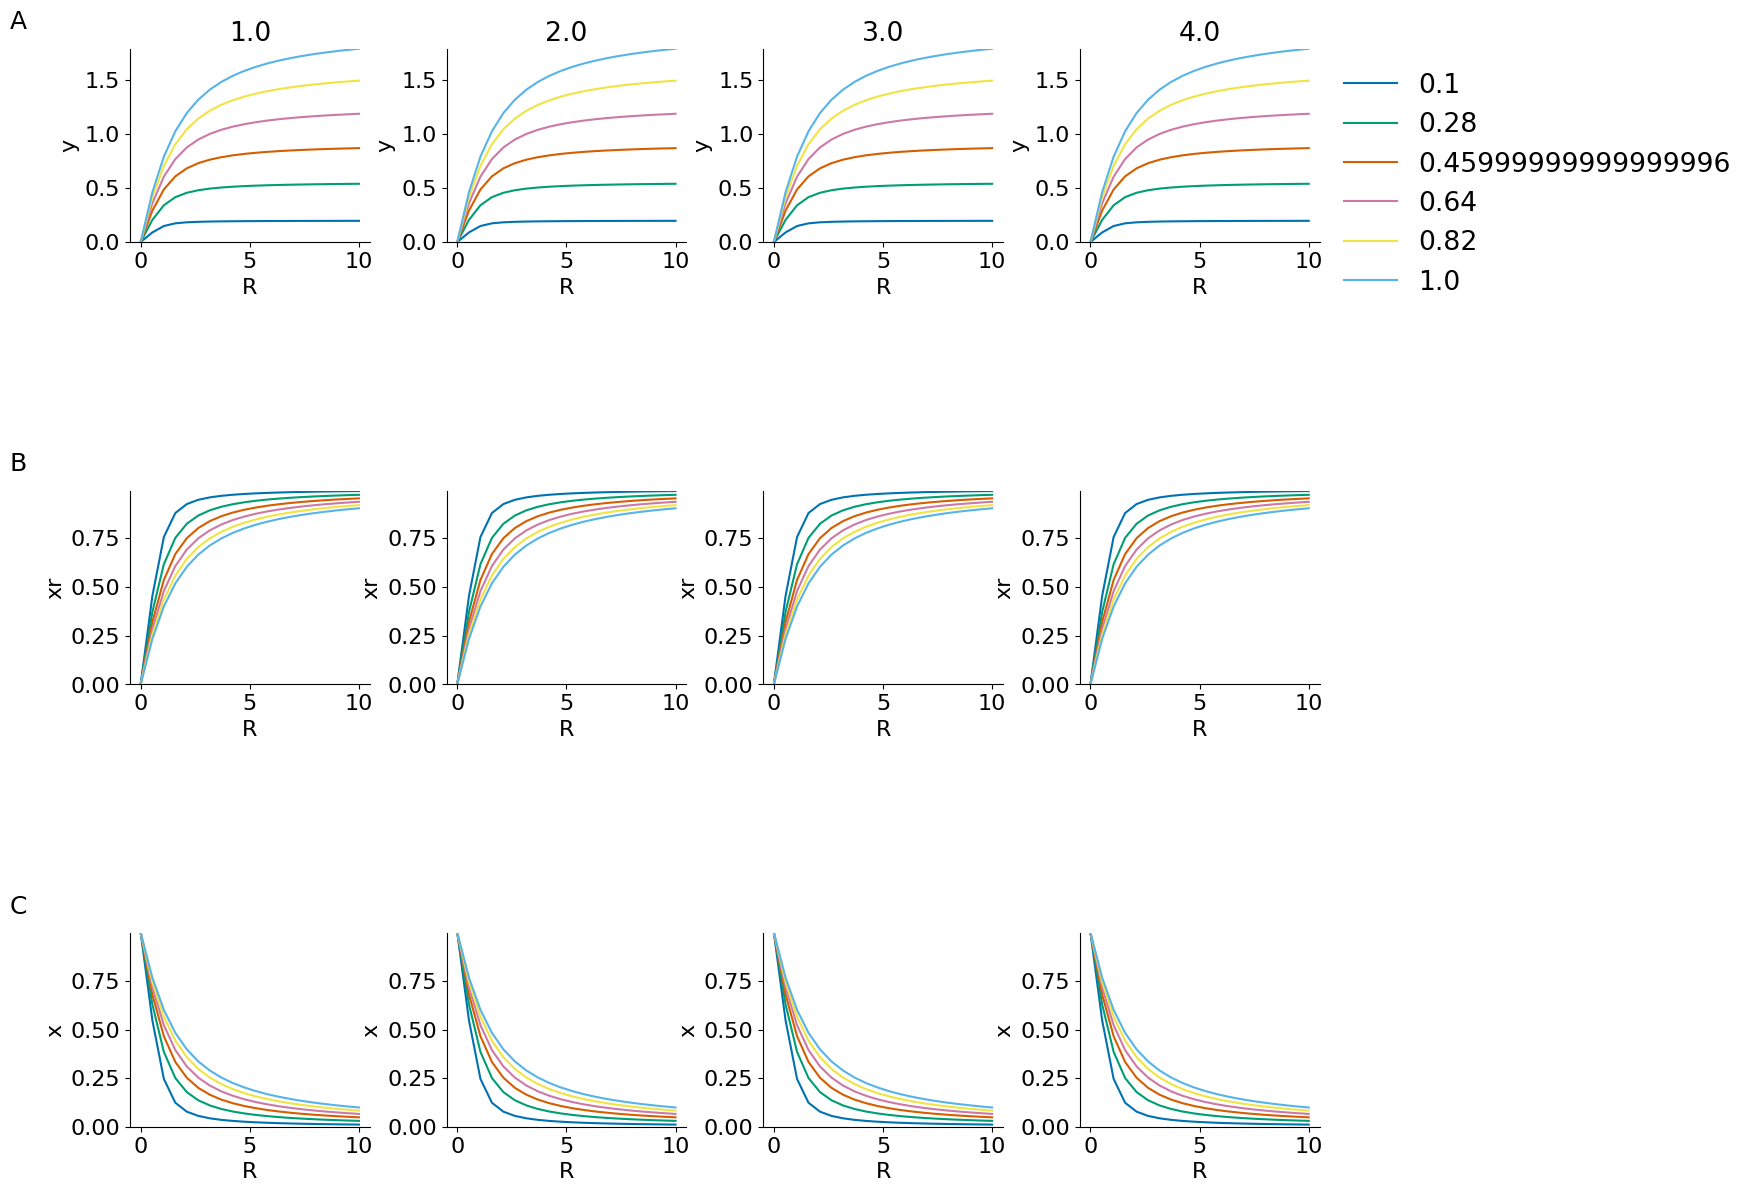

In [18]:
layout = '''
    AAAAAAAA
    AAAAAAAA
    BBBBBBBB
    BBBBBBBB
    CCCCCCCC
    
    '''


fig = plt.figure(figsize=(16, 14))

height_ratios = [1,0.2,1,0.2,1]
width_ratios = [1,0.1,1,0.1,1,0.1,1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()

miny = np.amin(results[:,:,:,2])
maxy = np.amax(results[:,:,:,2])
minxr = np.amin(results[:,:,:,1])
maxxr = np.amax(results[:,:,:,1])
minx = np.amin(results[:,:,:,0])
maxx = np.amax(results[:,:,:,0])

for yind, yf in enumerate(Yfactor): 
    ax1 = fig.add_subplot(gs[0,yind*2])
    ax2 = fig.add_subplot(gs[2,yind*2])
    ax3 = fig.add_subplot(gs[4,yind*2])
    ax1.set_title(yf*2)
    l = np.linspace(0.1,1,n)
    β = α * l
    for b in range(βs.shape[0]):
        ax1.plot(Rs, results[yind,b,:,2], label = βs[b], color = palette[b])
        ax2.plot(Rs, results[yind,b,:,1], label = βs[b], color = palette[b])
        ax3.plot(Rs, results[yind,b,:,0], label = βs[b], color = palette[b])
    ax1.set_xlabel('R')
    ax2.set_xlabel('R')
    ax3.set_xlabel('R')
    ax1.set_ylabel('y')
    ax2.set_ylabel('xr')
    ax3.set_ylabel('x')
    ax1.set_ylim(0, maxy)
    ax2.set_ylim(0, maxxr)
    ax3.set_ylim(0, maxx)
    

    clear_axes(ax1)
    clear_axes(ax2)
    clear_axes(ax3)
ax1.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
plt.show()


1


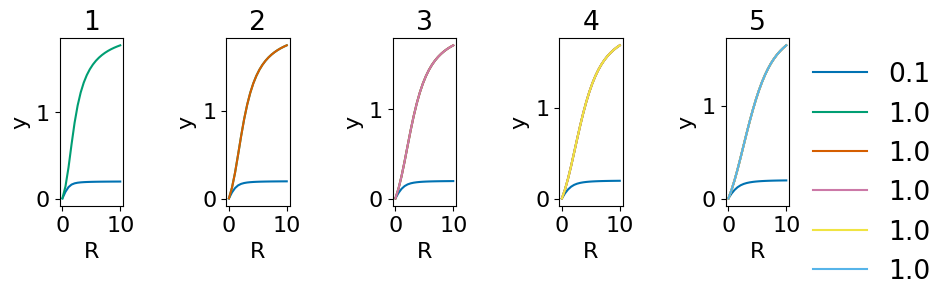

2


IndexError: list index out of range

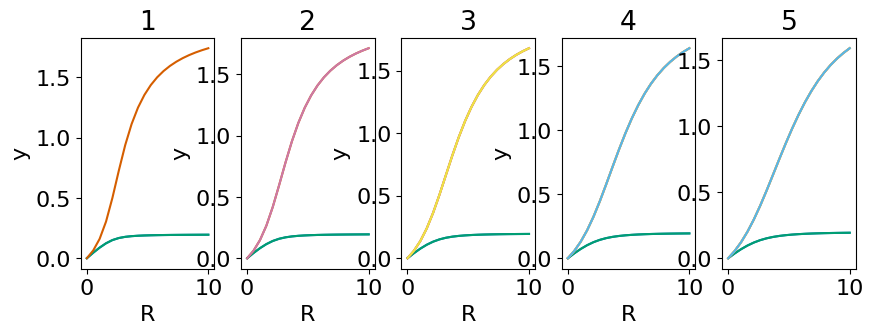

In [16]:
n = 2
yf = 1
m1s = np.arange(1,6,1)
m2s = np.arange(1,6,1)
results = np.zeros([m1s.shape[0], m2s.shape[0], Rs.shape[0], m1s[-1]+m2s[-1]])

for m1ind, m1 in enumerate(m1s): 
    for m2ind, m2  in enumerate(m2s): 
        l = np.linspace(0.1,1,n)
        parameters = dict()
        parameters['α'] = α
        ls = np.ones([m1+m2])
        ls[:m1] = l[0]
        ls[m1:] = l[1]
        parameters['γ'] = γ
        parameters['l'] = ls
        parameters['Y_max'] = n*yf

        #initial condition of all mRNA
        x0 = np.ones([m1+m2])*x_init
        βs = np.ones([m1+m2])
        βs[:m1] = l[0]
        βs[m1:] = l[1]
        parameters['β'] = α * βs
        
        for r in range(Rs.shape[0]):

            parameters['R'] = Rs[r]

            init_state =np.array([x0, np.zeros([m1+m2]),np.zeros([m1+m2])]) 

            baseline = simulation_wrapper(init_state,parameters,model_equation, sim_time, dt) 
            results[m1ind, m2ind, r, :m1+m2]= baseline[-1,2,:]


for m1ind, m1 in enumerate(m1s): 
    print(m1)
    fig, ax = plt.subplots(1,m2s.shape[0], figsize = (10,3))
    for m2ind, m2  in enumerate(m2s):
        ax[m2ind].set_title(m2)
        l = np.linspace(0.1,1,n)
        ls = np.ones([m1+m2])
        ls[:m1] = l[0]
        ls[m1:] = l[1]
        βs = np.ones([m1+m2])
        βs[:m1] = l[0]
        βs[m1:] = l[1]
        parameters['β'] = α * βs
        for i in range(m1+m2):
            ax[m2ind].plot(Rs, results[m1ind,m2ind,:,i], label = βs[i], color = palette[i])
        ax[m2ind].set_xlabel('R')
        ax[m2ind].set_ylabel('y')
    ax[m2ind].legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    fig.tight_layout()
    plt.show()

In [ ]:
for m1ind, m1 in enumerate(m1s): 
    print(str(m1) + ' long transcripts')
    fig, ax = plt.subplots(1,m2s.shape[0], figsize = (10,3))
    for m2ind, m2  in enumerate(m2s):
        ax[m2ind].set_title(str(m2)+' short transcripts')
        l = np.linspace(0.1,1,n)
        ls = np.ones([m1+m2])
        ls[:m1] = l[0]
        ls[m1:] = l[1]
        βs = np.ones([m1+m2])
        βs[:m1] = l[0]
        βs[m1:] = l[1]
        parameters['β'] = α * βs
        ax[m2ind].plot(Rs, np.sum(results[m1ind,m2ind,:,:m1], axis = 1), label = βs[0])
        ax[m2ind].plot(Rs, np.sum(results[m1ind,m2ind,:,m1:], axis = 1), label = βs[1])
        ax[m2ind].set_xlabel('R')
        ax[m2ind].set_ylabel('y')
    ax[m2ind].legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    fig.tight_layout()
    plt.show()
    
    
fig, ax = plt.subplots(1,m2s.shape[0], figsize = (10,3))    
for m1ind, m1 in enumerate(m1s): 
    for m2ind, m2  in enumerate(m2s):
        ax[m2ind].set_title(str(m2)+' short transcripts')
        l = np.linspace(0.1,1,n)
        ls = np.ones([m1+m2])
        ls[:m1] = l[0]
        ls[m1:] = l[1]
        βs = np.ones([m1+m2])
        βs[:m1] = l[0]
        βs[m1:] = l[1]
        parameters['β'] = α * βs
        ax[m2ind].plot(Rs, np.sum(results[m1ind,m2ind,:,:m1], axis = 1)/np.sum(results[m1ind,m2ind,:,m1:], axis = 1) , label = m1)
        ax[m2ind].set_xlabel('R')
        ax[m2ind].set_ylabel('$\\frac{x_{short}}{x_{long}}$')
ax[m2ind].legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
fig.tight_layout()
plt.show()

These effects are the product of interactions between \alpha and \beta, as well as R and Y_max. If Y_max is small the competition is seen at smaller beta. At large quatities of Y_max, beta needs to be large as well as R. However, I would not state here that R is the causal factor. You might be able to mitigate some of the imbalance by reducing ribosome numbers, but the cause is in the availabiltity of protein building blocks and the initiaiton/elongation rate. 